# 02 - Exploratory Data Analysis (EDA)

**Input:** `data/processed/order_category.csv` (created by notebook 01).
**Output:** figures, a category summary table, and a small configuration file (`study_config.json`) used by the next notebooks.

## What we want to learn here
| Question | Why it matters |
|---|---|
| Which weeks can we use? | Notebook 01 showed almost no orders before 2017 and a partial last week |
| Which categories have enough orders every week? | Weekly forecasting needs volume; small categories are just noise |
| How does the satisfaction score behave over time and by category? | This is our "sentiment" signal: it must vary to be useful |
| Do late deliveries explain bad reviews? | If yes, we must control for delivery delay in the models |
| Is there any early relationship between last week's sentiment and this week's orders? | A first, exploratory look (the real test is the forecasting experiment) |

## Conventions used in all notebooks
- A **week** starts on Monday (`purchase_week` = Monday of the purchase week).
- **Demand** of a category in a week = number of distinct delivered orders containing that category.
- **Sentiment** of a category in a week = average review score of reviews **answered** that week (the date the information becomes known).

> EDA is for understanding, not for proving anything. Correlations here are only a first hint.

## 1. Setup, parameters and loading

The block of **parameters** below is what we may change after looking at the results. Everything else adapts automatically.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

PROCESSED = Path("../data/processed")
FIGURES = Path("../outputs/figures")
TABLES = Path("../outputs/tables")
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# ----- Parameters (to be confirmed after looking at section 2) -----
START_WEEK = "2017-02-06"          # first Monday of the study period
END_WEEK = "2018-08-06"            # last Monday of the study period (last full week)
MIN_AVG_WEEKLY_ORDERS = 40         # a category must average at least this many orders per week
MIN_REVIEWS_PER_WEEK = 10          # weekly sentiment is only trusted with at least this many reviews

In [3]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "review_creation_date",
    "review_answer_timestamp",
]
master = pd.read_csv(PROCESSED / "order_category.csv", parse_dates=date_cols)
master["has_comment"] = master["has_comment"].astype(float)   # True/False/missing -> 1.0/0.0/NaN

# Monday of the week of each event
master["purchase_week"] = master["order_purchase_timestamp"].dt.to_period("W").dt.start_time
master["answer_week"] = master["review_answer_timestamp"].dt.to_period("W").dt.start_time

print(f"Rows: {len(master):,}   Distinct orders: {master['order_id'].nunique():,}   Categories: {master['category'].nunique()}")
master.head(3)

Rows: 97,268   Distinct orders: 96,470   Categories: 74


,order_id,category,n_items,items_value,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_time_days,is_late,review_score,n_reviews,review_creation_date,review_answer_timestamp,has_comment,purchase_week,answer_week
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,1,58.9,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,-8.011250,7.614421,False,5.0,1.0,2017-09-21,2017-09-22 10:57:03,1.0,2017-09-11,2017-09-18
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,1,239.9,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,-2.330278,16.216181,False,4.0,1.0,2017-05-13,2017-05-15 11:34:13,0.0,2017-04-24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,1,199.0,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,-13.444954,7.948437,False,5.0,1.0,2018-01-23,2018-01-23 16:06:31,1.0,2018-01-08,2018-01-22


## 2. Choosing the study period

We count distinct orders per week (all categories together) and look at the **beginning** and the **end** of the series.
Reasons to cut the edges:
- At the beginning, the marketplace was just starting: a handful of orders per week is not a demand to forecast.
- At the end, the last weeks are incomplete (the data stops, and we only keep *delivered* orders, so very recent orders are missing).

In [4]:
orders_unique = master.drop_duplicates("order_id")
weekly_total = orders_unique.groupby("purchase_week")["order_id"].count()

print("First 14 weeks:")
print(weekly_total.head(14).to_string())
print("\nLast 8 weeks:")
print(weekly_total.tail(8).to_string())

First 14 weeks:
purchase_week
2016-09-12      1
2016-10-03    231
2016-10-10     34
2016-12-19      1
2017-01-02     44
2017-01-09     73
2017-01-16    189
2017-01-23    332
2017-01-30    432
2017-02-06    511
2017-02-13    379
2017-02-20    349
2017-02-27    461
2017-03-06    548

Last 8 weeks:
purchase_week
2018-07-09     972
2018-07-16    1649
2018-07-23    1610
2018-07-30    2002
2018-08-06    1931
2018-08-13    1839
2018-08-20    1054
2018-08-27     116


Study period: 2017-02-06 -> 2018-08-06  =  79 weeks


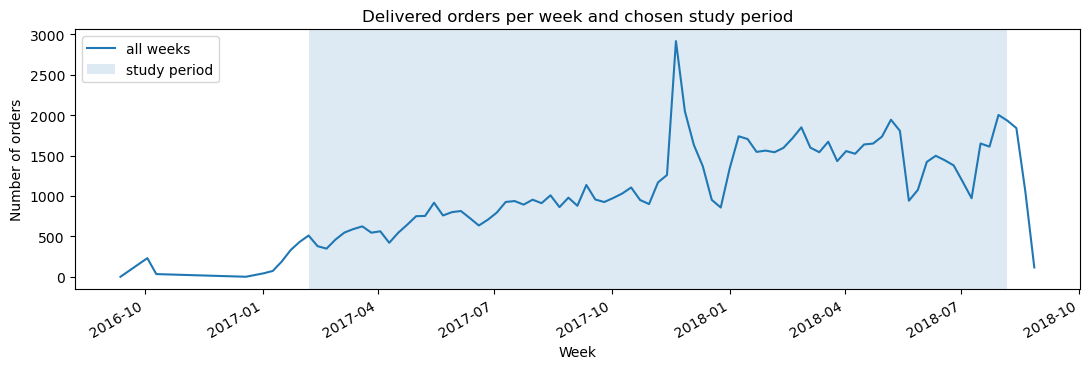

In [5]:
start, end = pd.Timestamp(START_WEEK), pd.Timestamp(END_WEEK)
weeks = pd.date_range(start, end, freq="W-MON")
print(f"Study period: {start.date()} -> {end.date()}  =  {len(weeks)} weeks")

fig, ax = plt.subplots(figsize=(11, 3.8))
weekly_total.plot(ax=ax, label="all weeks")
ax.axvspan(start, end, alpha=0.15, label="study period")
ax.set_title("Delivered orders per week and chosen study period")
ax.set_xlabel("Week")
ax.set_ylabel("Number of orders")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / "02_study_period.png", dpi=150)
plt.show()

**Decision to take:** does the shaded area start after the "ramp-up" and stop before the last incomplete weeks?
If not, change `START_WEEK` / `END_WEEK` in section 1 and run again from the top. Keep **Mondays**.

**Also look at the series:** there is a very high peak in November 2017 (Black Friday period) and some dips in 2018.
Holidays and events (hypotheses to check, not facts): Black Friday in late November 2017, and the national truckers' strike and the World Cup around May-July 2018.
These are "special weeks" that the models will find hard to predict, and the rolling test windows will show how they handle them.

In [6]:
weekly_in_window = weekly_total.reindex(weeks, fill_value=0)
print("Five busiest weeks in the study period:")
print(weekly_in_window.sort_values(ascending=False).head(5).to_string())
print(f"\nAverage orders per week: {weekly_in_window.mean():.0f}  (min {weekly_in_window.min()}, max {weekly_in_window.max()})")

Five busiest weeks in the study period:
2017-11-20    2915
2017-11-27    2046
2018-07-30    2002
2018-05-07    1943
2018-08-06    1931

Average orders per week: 1166  (min 349, max 2915)


## 3. Weekly panels: demand and sentiment per category

We build two tables whose **rows are weeks** and **columns are categories**:
- `orders_w`: number of distinct orders (demand);
- `sent_mean`: average review score, with `sent_n` = number of reviews behind each average.

A weekly average based on 2 reviews is too noisy, so averages with fewer than `MIN_REVIEWS_PER_WEEK` reviews are set to missing.

In [7]:
orders_w = (
    master.groupby(["purchase_week", "category"])["order_id"].nunique()
    .unstack("category", fill_value=0)
    .reindex(weeks, fill_value=0)
)

rev = master.dropna(subset=["review_score"])
sent_mean = (
    rev.groupby(["answer_week", "category"])["review_score"].mean()
    .unstack("category").reindex(weeks).reindex(columns=orders_w.columns)
)
sent_n = (
    rev.groupby(["answer_week", "category"])["order_id"].nunique()
    .unstack("category").reindex(weeks).reindex(columns=orders_w.columns).fillna(0)
)
sent_mean = sent_mean.where(sent_n >= MIN_REVIEWS_PER_WEEK)

print("orders_w :", orders_w.shape, "(weeks x categories)")
print("sent_mean:", sent_mean.shape)

orders_w : (79, 74) (weeks x categories)
sent_mean: (79, 74)


## 4. Which categories are usable?

For each category (inside the study period) we compute:
- **volume**: total and average weekly orders, and number of weeks with **zero** orders;
- **variability** of demand (`cv` = standard deviation / mean): a series that never moves is not interesting to forecast;
- **reviews**: average number of reviews per week and how much the weekly sentiment moves (`sentiment_std`);
- **context**: average score, share of late deliveries, share of reviews with a written comment.

A category is **eligible** if it averages at least `MIN_AVG_WEEKLY_ORDERS` orders per week and has no empty week.

In [8]:
in_window = master[(master["purchase_week"] >= start) & (master["purchase_week"] <= end)]

summary = pd.DataFrame({
    "total_orders": orders_w.sum(),
    "avg_weekly_orders": orders_w.mean(),
    "cv_orders": orders_w.std() / orders_w.mean(),
    "zero_weeks": (orders_w == 0).sum(),
    "avg_weekly_reviews": sent_n.mean(),
    "sentiment_std": sent_mean.std(),
})
context = in_window.groupby("category").agg(
    avg_score=("review_score", "mean"),
    late_rate=("is_late", "mean"),
    comment_rate=("has_comment", "mean"),
)
summary = summary.join(context)
summary["eligible"] = (summary["avg_weekly_orders"] >= MIN_AVG_WEEKLY_ORDERS) & (summary["zero_weeks"] == 0)
summary = summary.sort_values("total_orders", ascending=False)

n_eligible = int(summary["eligible"].sum())
coverage = summary.loc[summary["eligible"], "total_orders"].sum() / summary["total_orders"].sum()
print(f"Categories in the study period: {len(summary)}")
print(f"Eligible categories           : {n_eligible}  (they cover {coverage:.0%} of all orders)")
print(f"Orders with 'unknown' category: {(in_window['category'] == 'unknown').mean():.1%}")

summary.round(2).head(25)

Categories in the study period: 74
Eligible categories           : 12  (they cover 70% of all orders)
Orders with 'unknown' category: 1.5%


,total_orders,avg_weekly_orders,cv_orders,zero_weeks,avg_weekly_reviews,sentiment_std,avg_score,late_rate,comment_rate,eligible
category,,,,,,,,,,
bed_bath_table,8925,112.97,0.43,0,109.33,0.25,3.99,0.09,0.46,True
health_beauty,8118,102.76,0.54,0,98.63,0.21,4.22,0.09,0.38,True
sports_leisure,7206,91.22,0.43,0,89.19,0.23,4.22,0.08,0.38,True
computers_accessories,6306,79.82,0.59,0,77.05,0.23,4.07,0.08,0.41,True
furniture_decor,5926,75.01,0.42,0,73.57,0.22,4.05,0.09,0.40,True
housewares,5431,68.75,0.48,0,65.63,0.20,4.18,0.07,0.40,True
watches_gifts,5303,67.13,0.65,0,64.22,0.24,4.12,0.09,0.44,True
telephony,3957,50.09,0.45,0,48.43,0.26,4.04,0.09,0.44,True
toys,3650,46.20,0.67,0,45.35,0.26,4.24,0.08,0.37,True


In [9]:
summary.round(3).to_csv(TABLES / "02_category_summary.csv")
print("Saved:", TABLES / "02_category_summary.csv")

Saved: ..\outputs\tables\02_category_summary.csv


**How to read the table**
- `avg_weekly_orders`: the larger, the more stable the weekly count.
- `cv_orders`: a high value means the demand moves a lot (more to forecast, but harder).
- `avg_weekly_reviews` and `sentiment_std`: we need enough reviews each week **and** a sentiment that actually changes over time.
- `late_rate`: categories with more late deliveries are the ones where sentiment and logistics are most mixed up.

A good **main category** for the deep analysis has: high volume, enough demand variability, enough reviews every week, and a sentiment that moves.
We will choose it together after looking at this table (and Alan's answer about focusing on one category).

## 5. Demand and sentiment of the biggest categories

Six biggest known categories, weekly demand on the first row, weekly sentiment on the second row.
Gaps in the sentiment line mean fewer than `MIN_REVIEWS_PER_WEEK` reviews that week.

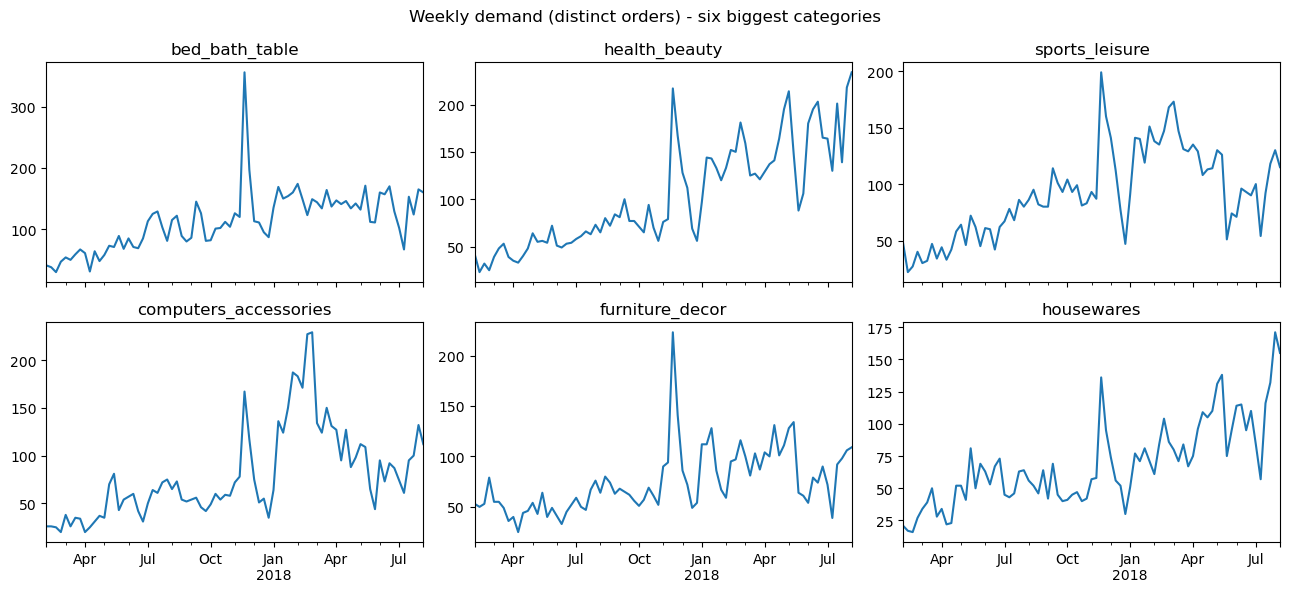

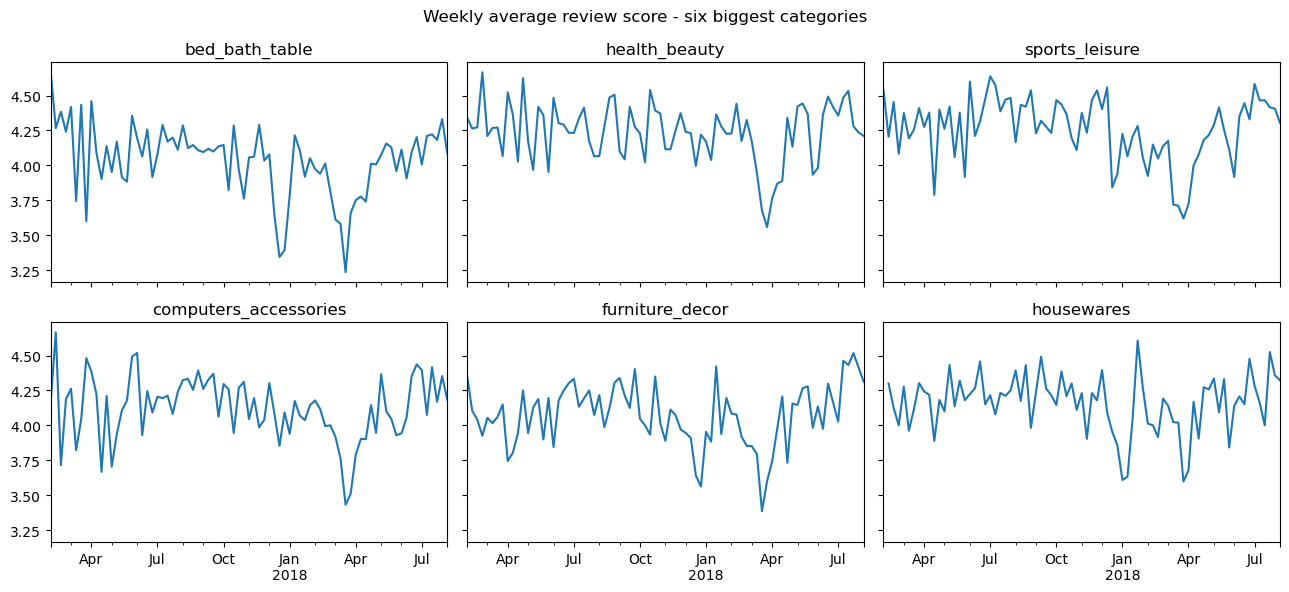

In [10]:
top = [c for c in summary.index if c != "unknown"][:6]

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, c in zip(axes.ravel(), top):
    orders_w[c].plot(ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Weekly demand (distinct orders) - six biggest categories")
plt.tight_layout()
fig.savefig(FIGURES / "02_top_categories_demand.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), top):
    sent_mean[c].plot(ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Weekly average review score - six biggest categories")
plt.tight_layout()
fig.savefig(FIGURES / "02_top_categories_sentiment.png", dpi=150)
plt.show()

## 6. The review score: distribution and evolution

We use **one row per order** here (not per category), so no order is counted twice.

review_score
1.0     9.7
2.0     3.1
3.0     8.3
4.0    19.8
5.0    59.2


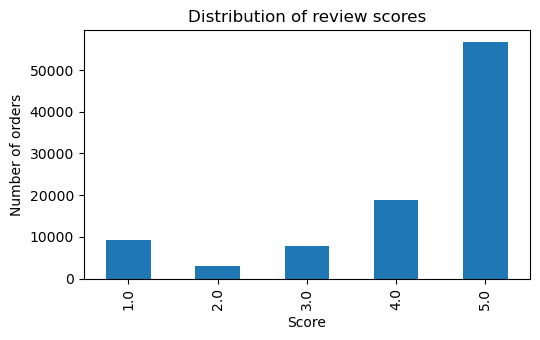

In [11]:
order_level = master.drop_duplicates("order_id").dropna(subset=["review_score"]).copy()

score_counts = order_level["review_score"].round().value_counts().sort_index()
print((score_counts / score_counts.sum()).mul(100).round(1).rename("% of reviewed orders").to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.5))
score_counts.plot.bar(ax=ax)
ax.set_title("Distribution of review scores")
ax.set_xlabel("Score")
ax.set_ylabel("Number of orders")
plt.tight_layout()
fig.savefig(FIGURES / "02_score_distribution.png", dpi=150)
plt.show()

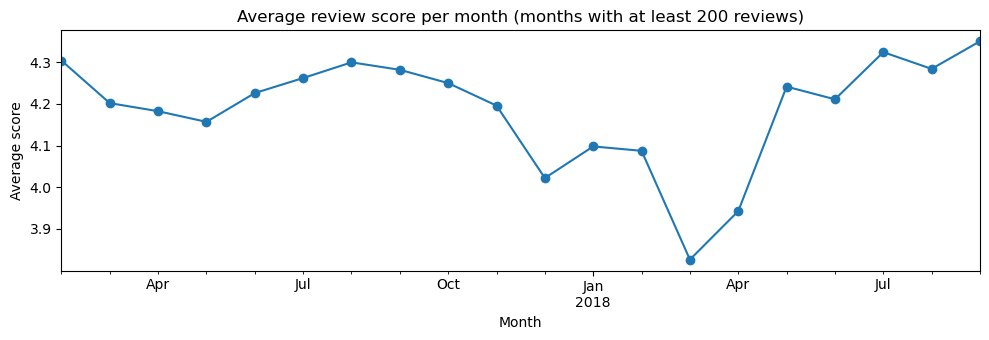

In [12]:
order_level["answer_month"] = order_level["review_answer_timestamp"].dt.to_period("M").dt.to_timestamp()
monthly = order_level.groupby("answer_month")["review_score"].agg(avg_score="mean", n_reviews="count")
monthly = monthly[monthly["n_reviews"] >= 200]

fig, ax = plt.subplots(figsize=(10, 3.5))
monthly["avg_score"].plot(ax=ax, marker="o")
ax.set_title("Average review score per month (months with at least 200 reviews)")
ax.set_xlabel("Month")
ax.set_ylabel("Average score")
plt.tight_layout()
fig.savefig(FIGURES / "02_monthly_score.png", dpi=150)
plt.show()

## 7. Do late deliveries explain bad reviews?

We group orders by how early or late they arrived compared with the promised date, and look at the average score of each group.
If late orders have a much lower score, then our sentiment signal partly measures **logistics**, and the delivery delay must be a control variable in the models.

               orders  avg_score
delay_bucket                    
early (>7 d)    70929       4.32
early (0-7 d)   17234       4.20
late (0-3 d)     2636       3.77
late (3-7 d)     1773       2.32
late (>7 d)      3252       1.73

Spearman correlation between delay and score: -0.18


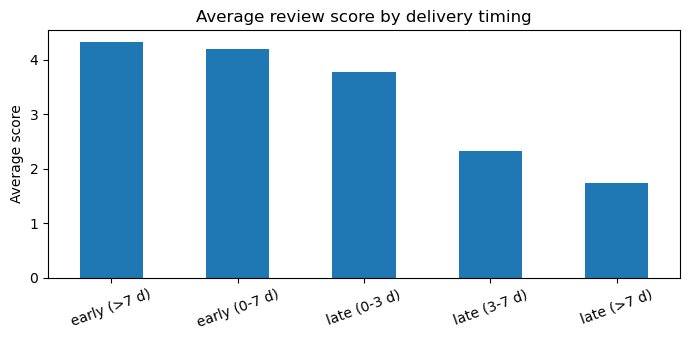

In [13]:
bins = [-np.inf, -7, 0, 3, 7, np.inf]
labels = ["early (>7 d)", "early (0-7 d)", "late (0-3 d)", "late (3-7 d)", "late (>7 d)"]
order_level["delay_bucket"] = pd.cut(order_level["delivery_delay_days"], bins=bins, labels=labels)

delay_table = (
    order_level.groupby("delay_bucket", observed=True)
    .agg(orders=("order_id", "count"), avg_score=("review_score", "mean"))
    .round(2)
)
print(delay_table.to_string())

rho = order_level[["delivery_delay_days", "review_score"]].corr(method="spearman").iloc[0, 1]
print(f"\nSpearman correlation between delay and score: {rho:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
delay_table["avg_score"].plot.bar(ax=ax)
ax.set_title("Average review score by delivery timing")
ax.set_xlabel("")
ax.set_ylabel("Average score")
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(FIGURES / "02_delay_vs_score.png", dpi=150)
plt.show()

## 8. A first look: last week's sentiment vs this week's demand

For each eligible category we compare:
- **levels**: sentiment of week *t-1* vs orders of week *t*. Careful: both series grow or fall together over time, which creates correlations that mean nothing (a "trend illusion").
- **changes**: change in sentiment from *t-2* to *t-1* vs change in orders from *t-1* to *t*. This removes the trend and is more honest.

This is **only exploratory**. A weak correlation here does not kill the project: the forecasting models can use sentiment together with other variables, and are tested properly with rolling windows.

In [14]:
eligible = list(summary.index[summary["eligible"]])

rows = []
for c in eligible:
    s, o = sent_mean[c], orders_w[c]
    rows.append({
        "category": c,
        "corr_levels": s.shift(1).corr(o),
        "corr_changes": s.diff().shift(1).corr(o.diff()),
        "weeks_with_sentiment": int(s.notna().sum()),
    })

lag_corr = pd.DataFrame(rows).set_index("category").sort_values("corr_changes")
print(lag_corr.round(2).to_string())
print(f"\nAverage correlation (levels) : {lag_corr['corr_levels'].mean():.2f}")
print(f"Average correlation (changes): {lag_corr['corr_changes'].mean():.2f}")

lag_corr.round(3).to_csv(TABLES / "02_lagged_correlations.csv")

                       corr_levels  corr_changes  weeks_with_sentiment
category                                                              
auto                         -0.21         -0.18                    77
cool_stuff                   -0.22         -0.13                    78
health_beauty                -0.15         -0.13                    79
sports_leisure               -0.27         -0.08                    79
computers_accessories        -0.26         -0.07                    79
garden_tools                  0.06         -0.04                    77
telephony                    -0.28         -0.03                    78
bed_bath_table               -0.22          0.01                    79
housewares                   -0.03          0.04                    78
watches_gifts                -0.28          0.12                    73
furniture_decor              -0.07          0.13                    79
toys                          0.05          0.16                    78

Avera

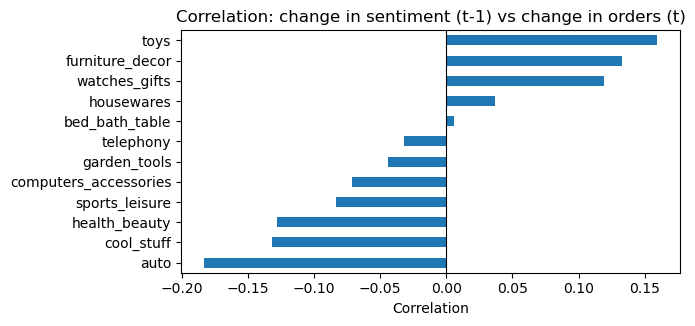

In [15]:
fig, ax = plt.subplots(figsize=(7, max(3, 0.28 * len(lag_corr))))
lag_corr["corr_changes"].plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation: change in sentiment (t-1) vs change in orders (t)")
ax.set_xlabel("Correlation")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(FIGURES / "02_lagged_correlations.png", dpi=150)
plt.show()

## 9. Save the decisions for the next notebooks

We store the study period and the list of eligible categories in a small JSON file. Notebook 03 reads it, so the choices are made **once** and stay consistent.

In [16]:
config = {
    "start_week": START_WEEK,
    "end_week": END_WEEK,
    "n_weeks": int(len(weeks)),
    "min_avg_weekly_orders": MIN_AVG_WEEKLY_ORDERS,
    "min_reviews_per_week": MIN_REVIEWS_PER_WEEK,
    "eligible_categories": eligible,
}
with open(PROCESSED / "study_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"Saved study_config.json: {len(weeks)} weeks, {len(eligible)} eligible categories")

Saved study_config.json: 79 weeks, 12 eligible categories


## Summary: what to write in the report (EDA chapter, ~1000 words)
- The study period (dates, number of weeks) and **why** the edges were removed (section 2).
- The shape of demand: strong growth in 2017, the November 2017 peak, dips in 2018 (sections 2 and 5).
- How many categories are eligible and what share of orders they cover (section 4).
- The distribution of review scores and its evolution (section 6).
- The link between late delivery and low scores, and what it implies for the models (section 7).
- The exploratory lagged correlations, with the "trend illusion" caveat (section 8).
- Every figure needs a numbered caption and one sentence saying what it shows **for the business**.

**Next notebook:** `03_features_and_baselines.ipynb` - build the final forecasting table, the rolling test windows and the baselines.

**Suggested commit message:** `Add notebook 02: exploratory data analysis and study configuration`